In [1]:
%load_ext autoreload
%autoreload 2

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm


from pygraphon.graphons import graphon_log, graphon_logit_sum
from pygraphon.utils.utils_graph import edge_density
from pygraphon.graphons.StepGraphon import StepGraphon
from pygraphon.plots.plot_matrices import spy

from pygraphon.estimators import HistogramEstimator, SAS
from pygraphon.norm import MseProbaEdge

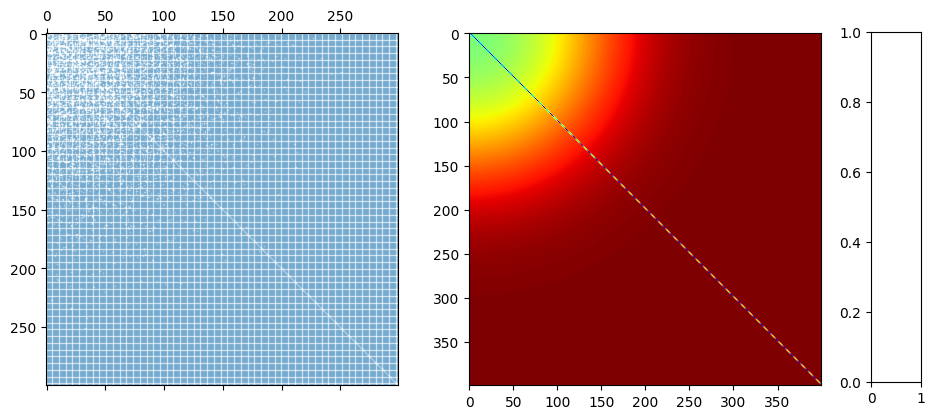

In [27]:
#Set the matrix of theta
graphon_matrix = np.array([[0.8,0.1,0.1],[0.1,0.8,0.1],[0.1,0.1,0.8]])
#set up normalised graphon with graphon
graphon = StepGraphon(graphon_matrix,1/3)
graphon = graphon_logit_sum


A = graphon.draw(rho = 1,n = 300, exchangeable=False)
norm = MseProbaEdge(n_nodes = 500)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im = ax[1].imshow(graphon._get_edge_probabilities(400,False,True), cmap='jet')
_ = spy(A, ax=ax[0])
#ax[0].imshow(A.astype(int), cmap='jet')
plt.show()

Initial log-likelihood: -6058.833898021178
fast normalized ll: -0.1350910568120664
Initial normalized log-likelihood: -0.1430893866287504


LL: -0.0375,  3 global improvements:  12%|█▏        | 60/500 [00:53<06:34,  1.12it/s]


3 consecutive likelihood improvements less than specified tolerance; quitting now
Best LL: -0.0375


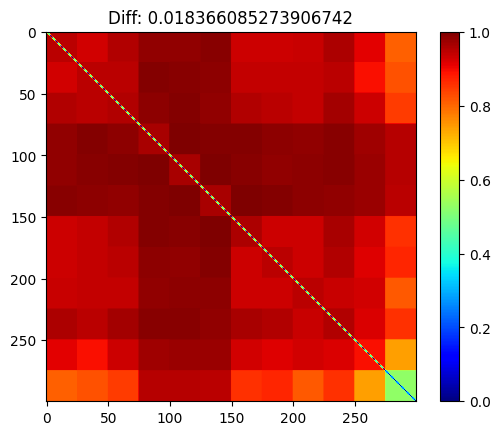

In [29]:
hist = HistogramEstimator()
hist.fit(graph= A, bandwidthHist= None, method = "matlab")
diff = norm(graphon, hist)
plt.imshow(hist.get_graphon()._get_edge_probabilities(300,False,True), cmap = "jet")
plt.title(f"Diff: {diff}")
plt.colorbar()

Likelihood: -0.1276:   3%|▎         | 13/500 [00:04<02:56,  2.75it/s]                


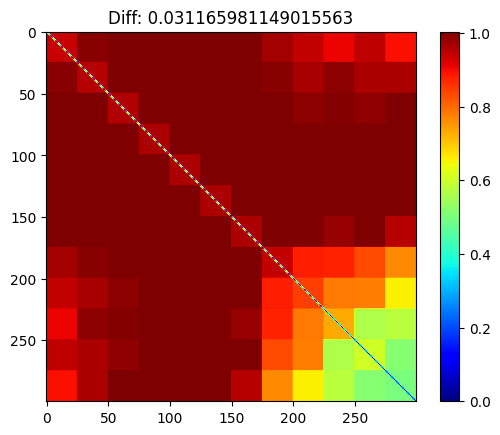

In [30]:
my_hist = HistogramEstimator()
my_hist.fit(graph= A, bandwidthHist= None, method = "mine")
diff = norm(graphon, my_hist)
plt.imshow(my_hist.get_graphon()._get_edge_probabilities(300,False,True), cmap = "jet")
plt.title(f"Diff: {diff}")
plt.colorbar()